# Telco Customer Churn – 5 Classification Models
## ML Assignment 2
## Name: Soumyajit De
## BITS ID: 2026CT05037

In [1]:
%matplotlib inline
import os, joblib, numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)

SEED = 42
# Run this notebook from the model/ folder (ROOT = project folder)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd())=="model" else os.getcwd()
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)

Shape: (7043, 21)
Missing values:
 TotalCharges    11
dtype: int64
Duplicates: 22
Class distribution:
 Churn
No     5164
Yes    1857
Name: count, dtype: int64 
 Churn
No     0.736
Yes    0.264
Name: proportion, dtype: float64


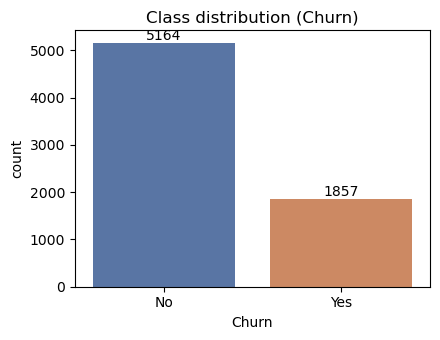

In [2]:
#Step 1: load dataset
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_URL)   # loaded directly from the link
print("Shape:", df.shape)
df = df.drop(columns=["customerID"])                       # identifier, no predictive value
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # blanks -> NaN
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Class distribution:\n", df["Churn"].value_counts(), "\n", df["Churn"].value_counts(normalize=True).round(3))

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns="Churn")

plt.figure(figsize=(4.5, 3.5))
ax = sns.countplot(x=df["Churn"], hue=df["Churn"], palette=["#4c72b0", "#dd8452"], legend=False)
for c in ax.containers: ax.bar_label(c)
plt.title("Class distribution (Churn)"); plt.tight_layout(); plt.savefig(f"{RES}/class_distribution.png", dpi=150); plt.show()

In [3]:
#Step 2:Data preprocessing ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train/test:", X_train.shape, X_test.shape,
      "| churn rate train %.3f test %.3f" % (y_train.mean(), y_test.mean()))

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
# SeniorCitizen is already 0/1; keep it numeric but don't scale it.
num_scale = ["tenure", "MonthlyCharges", "TotalCharges"]
passthrough = [c for c in num_cols if c not in num_scale]

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_scale),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
        ("pass", "passthrough", passthrough),
    ])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=300, max_depth=10,
                                                       min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}

Train/test: (5616, 19) (1405, 19) | churn rate train 0.264 test 0.265


In [4]:
#Step 3: train models
rows = []
for name, clf in models.items():
    pipe = Pipeline([("pre", make_pre()), ("clf", clf)])   # preprocessing fitted on train only
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({"ML Model Name": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "AUC": roc_auc_score(y_test, proba),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "MCC": matthews_corrcoef(y_test, pred)})
    joblib.dump(pipe, os.path.join(ROOT, "model", name.split(" (")[0].lower().replace(" ", "_") + ".pkl"))

from IPython.display import display
res = pd.DataFrame(rows).round(4)
res.to_csv(f"{RES}/metrics_comparison.csv", index=False)
print("\n", res.to_string(index=False))
display(res)

# test data (with target) for the repo
pd.concat([X_test, y_test.rename("Churn")], axis=1).to_csv(os.path.join(ROOT, "test_data.csv"), index=False)


            ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
     Logistic Regression    0.8021 0.8403     0.6588  0.5242 0.5838 0.4614
           Decision Tree    0.7950 0.8294     0.6228  0.5726 0.5966 0.4603
                     kNN    0.7900 0.8167     0.6199  0.5349 0.5743 0.4381
             Naive Bayes    0.6811 0.8110     0.4457  0.8387 0.5821 0.4087
Random Forest (Ensemble)    0.7986 0.8400     0.6561  0.5027 0.5693 0.4475


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8021,0.8403,0.6588,0.5242,0.5838,0.4614
1,Decision Tree,0.7950,0.8294,0.6228,0.5726,0.5966,0.4603
2,kNN,0.7900,0.8167,0.6199,0.5349,0.5743,0.4381
3,Naive Bayes,0.6811,0.8110,0.4457,0.8387,0.5821,0.4087
4,Random Forest (Ensemble),0.7986,0.8400,0.6561,0.5027,0.5693,0.4475


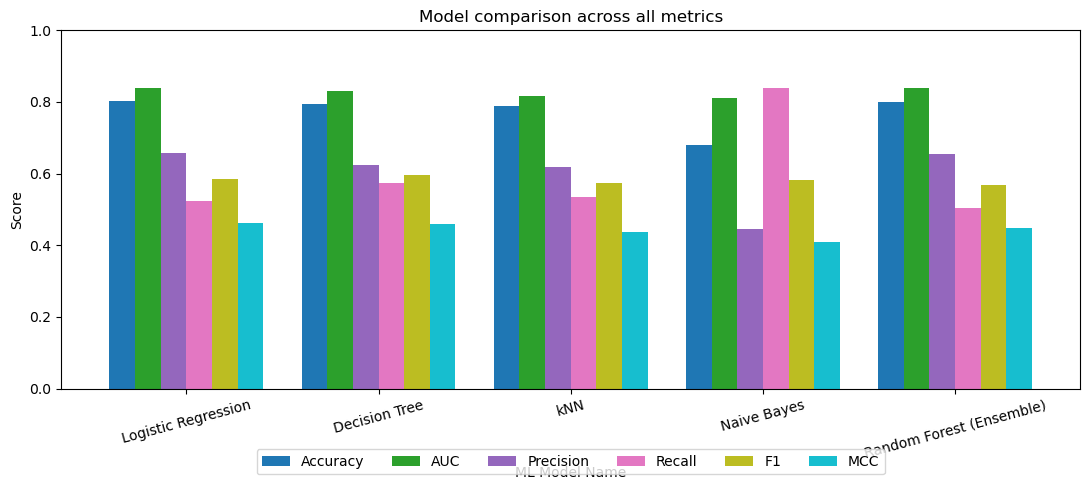

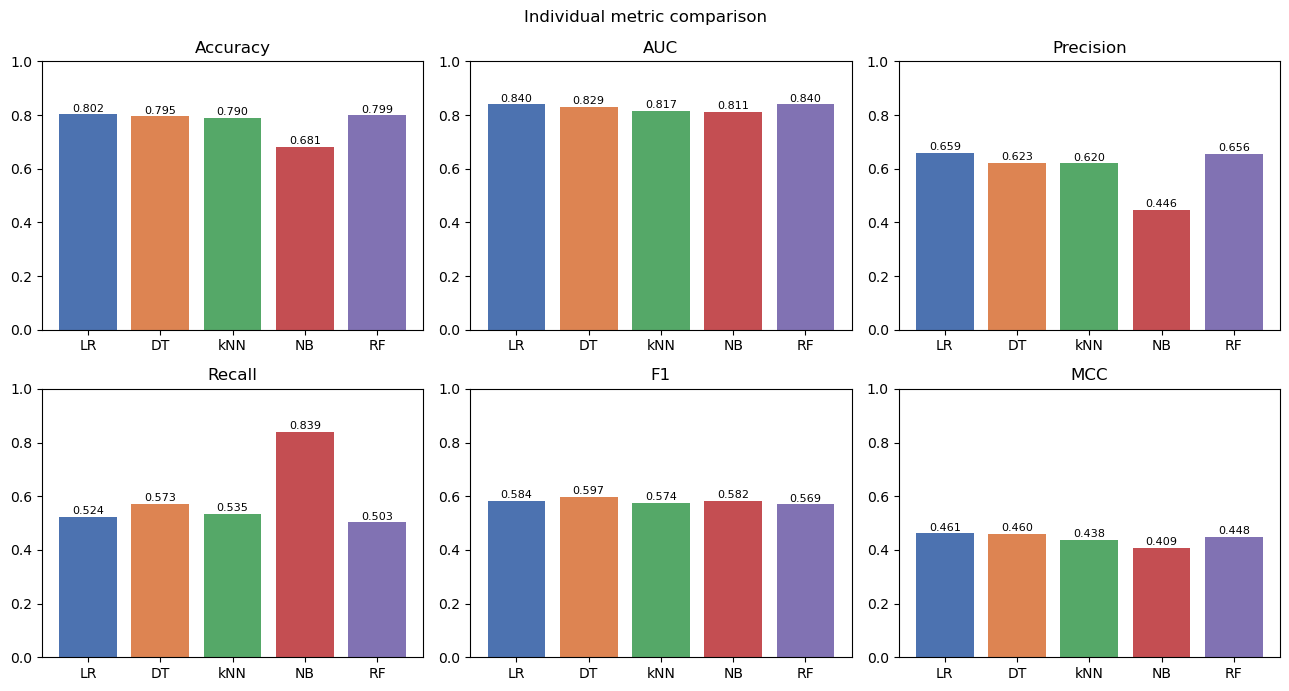

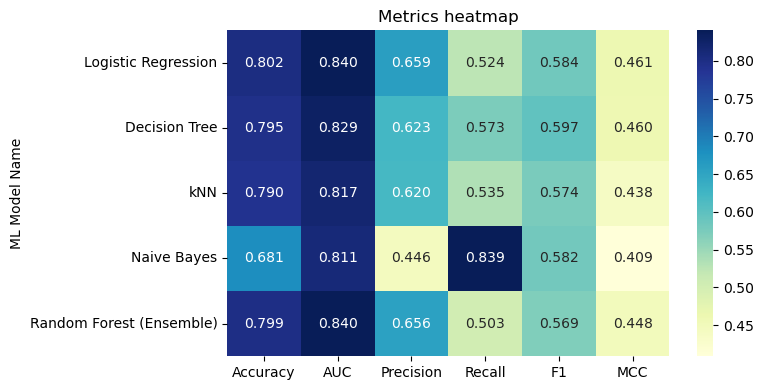

Done. Charts also saved in results folder


In [5]:
#Step 4: Prepare charts ----------
m = res.set_index("ML Model Name")
ax = m.plot(kind="bar", figsize=(11, 5), width=0.8, colormap="tab10")
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Model comparison across all metrics")
plt.xticks(rotation=15); plt.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.savefig(f"{RES}/metrics_grouped_bar.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, metric in zip(axes.ravel(), m.columns):
    vals = m[metric]; bars = ax.bar(range(len(vals)), vals, color=sns.color_palette("deep", 5))
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(["LR", "DT", "kNN", "NB", "RF"])
    ax.set_title(metric); ax.set_ylim(min(0, vals.min()), 1)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
plt.suptitle("Individual metric comparison"); plt.tight_layout(); plt.savefig(f"{RES}/metrics_per_metric.png", dpi=150); plt.show()

plt.figure(figsize=(8, 4)); sns.heatmap(m, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Metrics heatmap"); plt.tight_layout(); plt.savefig(f"{RES}/metrics_heatmap.png", dpi=150); plt.show()
print("Done. Charts also saved in results folder")